# Analyse des annotations Qwen3.8 Gyro-S

Ce notebook se concentre exclusivement sur les lignes d’annotations produites par Qwen3.8 Gyro-S. Il analyse leur couverture, la répartition des taxonomies et de la qualité, puis montre des exemples aléatoires avec leurs images et leurs étiquettes. Les annotations sont des prédictions automatiques : `auto_labeled` ne signifie pas qu’elles ont été validées par une personne.


In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime
import base64
import html
import json
import os
import random
from io import BytesIO

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from IPython.display import HTML, display
from huggingface_hub import HfApi, hf_hub_download

DATASET_REPO = 'ethanzxv/pixelart-dataset'
ANNOTATION_FILE_OVERRIDE = None  # Optionnel : chemin JSONL exact dans le dépôt HF.
HF_TOKEN = os.environ.get('HF_TOKEN') or os.environ.get('HUGGINGFACE_HUB_TOKEN') or True

# Racine locale du projet et JSONL produit par le run courant.
cwd = Path.cwd().resolve()
project_roots = [p for p in (cwd, *cwd.parents) if (p / 'notebook/dataset').is_dir()]
PROJECT_ROOT = project_roots[0] if project_roots else cwd
LOCAL_ANNOTATIONS = PROJECT_ROOT / 'notebook/dataset/taxonomy/taxonomy_work/annotations_v3_4_full_color.jsonl'

# Priorité : override explicite, fichier vivant local, puis snapshot Qwen3.8 le plus récent sur HF.
if ANNOTATION_FILE_OVERRIDE:
    annotation_path = Path(hf_hub_download(repo_id=DATASET_REPO, repo_type='dataset', filename=ANNOTATION_FILE_OVERRIDE, token=HF_TOKEN))
    annotation_source = ANNOTATION_FILE_OVERRIDE
elif LOCAL_ANNOTATIONS.is_file():
    annotation_path = LOCAL_ANNOTATIONS
    annotation_source = f'workspace · {LOCAL_ANNOTATIONS}'
else:
    api = HfApi(token=HF_TOKEN)
    files = api.list_repo_files(DATASET_REPO, repo_type='dataset')
    remote_candidates = [
        name for name in files
        if name.endswith('.jsonl') and (
            name.startswith('annotations/dataset_lab_sync/')
            or name.startswith('annotations/taxonomy_runs/')
        )
    ]
    remote_candidates.sort(reverse=True)
    annotation_path = None
    annotation_source = None
    for remote_name in remote_candidates:
        downloaded = Path(hf_hub_download(repo_id=DATASET_REPO, repo_type='dataset', filename=remote_name, token=HF_TOKEN))
        try:
            with downloaded.open(encoding='utf-8') as stream:
                first = next((json.loads(line) for line in stream if line.strip()), {})
            model_name = str(first.get('model', '')).lower()
            if 'qwen3.8' in model_name and 'gyro' in model_name:
                annotation_path, annotation_source = downloaded, remote_name
                break
        except (OSError, json.JSONDecodeError):
            continue
    if annotation_path is None:
        raise FileNotFoundError('Aucun JSONL Qwen3.8 Gyro-S trouvé localement ou dans les snapshots HF.')

# Snapshot cohérent du JSONL : une éventuelle dernière ligne incomplète est ignorée.
qwen_rows = []
with annotation_path.open('rb') as stream:
    while True:
        line = stream.readline()
        if not line or not line.endswith(b'\n'):
            break
        if line.strip():
            qwen_rows.append(json.loads(line))
qwen_rows = [
    row for row in qwen_rows
    if 'qwen3.8' in str(row.get('model', '')).lower()
    and 'gyro' in str(row.get('model', '')).lower()
]
if not qwen_rows:
    raise ValueError(f'Aucune annotation Qwen3.8 Gyro-S dans {annotation_source}')

print(f'{len(qwen_rows):,} lignes Qwen3.8 Gyro-S · {len({r.get("asset_id") for r in qwen_rows}):,} asset_id uniques')
print('Source :', annotation_source)


/home/eth/miniforge3/envs/iris-lora/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


3,836 lignes Qwen3.8 Gyro-S · 3,836 asset_id uniques
Source : workspace · /home/eth/Documents/Github/iris-pixelart/notebook/dataset/taxonomy/taxonomy_work/annotations_v3_4_full_color.jsonl


## État général des annotations

Les compteurs portent sur le JSONL Qwen3.8 chargé ci-dessus. Les doublons sont calculés sur `asset_id` ; les champs manquants et les statuts automatiques sont exposés séparément.


In [2]:
asset_ids = [row.get('asset_id') for row in qwen_rows]
model_counts = Counter(row.get('model', '(absent)') for row in qwen_rows)
review_counts = Counter(row.get('review_status', '(absent)') for row in qwen_rows)
quality_counts = Counter(row.get('labels', {}).get('visual_quality', '(absent)') for row in qwen_rows)
rework_counts = Counter(row.get('need_rework', '(absent)') for row in qwen_rows)
timestamps = [row.get('annotated_at_utc') for row in qwen_rows if row.get('annotated_at_utc')]
summary = pd.DataFrame([
    ('Lignes Qwen3.8 Gyro-S', len(qwen_rows)),
    ('asset_id uniques', len(set(asset_ids))),
    ('asset_id dupliqués', len(asset_ids) - len(set(asset_ids))),
    ('Première annotation (UTC)', min(timestamps) if timestamps else 'inconnue'),
    ('Dernière annotation (UTC)', max(timestamps) if timestamps else 'inconnue'),
    ('Modèles', ', '.join(f'{k}: {v}' for k, v in model_counts.items())),
], columns=['Mesure', 'Valeur'])
display(summary)
print('Statuts de revue :', dict(review_counts))
print('Qualité visuelle :', dict(quality_counts))
print('need_rework :', dict(rework_counts))


,Mesure,Valeur
0,Lignes Qwen3.8 Gyro-S,3790
1,asset_id uniques,3790
2,asset_id dupliqués,0
3,Première annotation (UTC),2026-11-10T09:53:58.770099+00:00
4,Dernière annotation (UTC),2026-11-12T10:07:46.111185+00:00
5,Modèles,qwen3.8-flash-next-gyro-gyro-s: 3790


Statuts de revue : {'auto_labeled': 3790}
Qualité visuelle : {'clean': 3753, 'minor_issues': 35, 'unknown': 1, 'needs_rework': 1}
need_rework : {False: 3788, None: 1, True: 1}


## Répartition des taxonomies

Chaque graphique présente jusqu’aux 12 valeurs les plus fréquentes d’un champ. Les listes, comme `dominant_color_families`, comptent une image au plus une fois par valeur. `unknown` et `not_applicable` sont visibles dans les répartitions, car ils renseignent la couverture réelle du modèle.


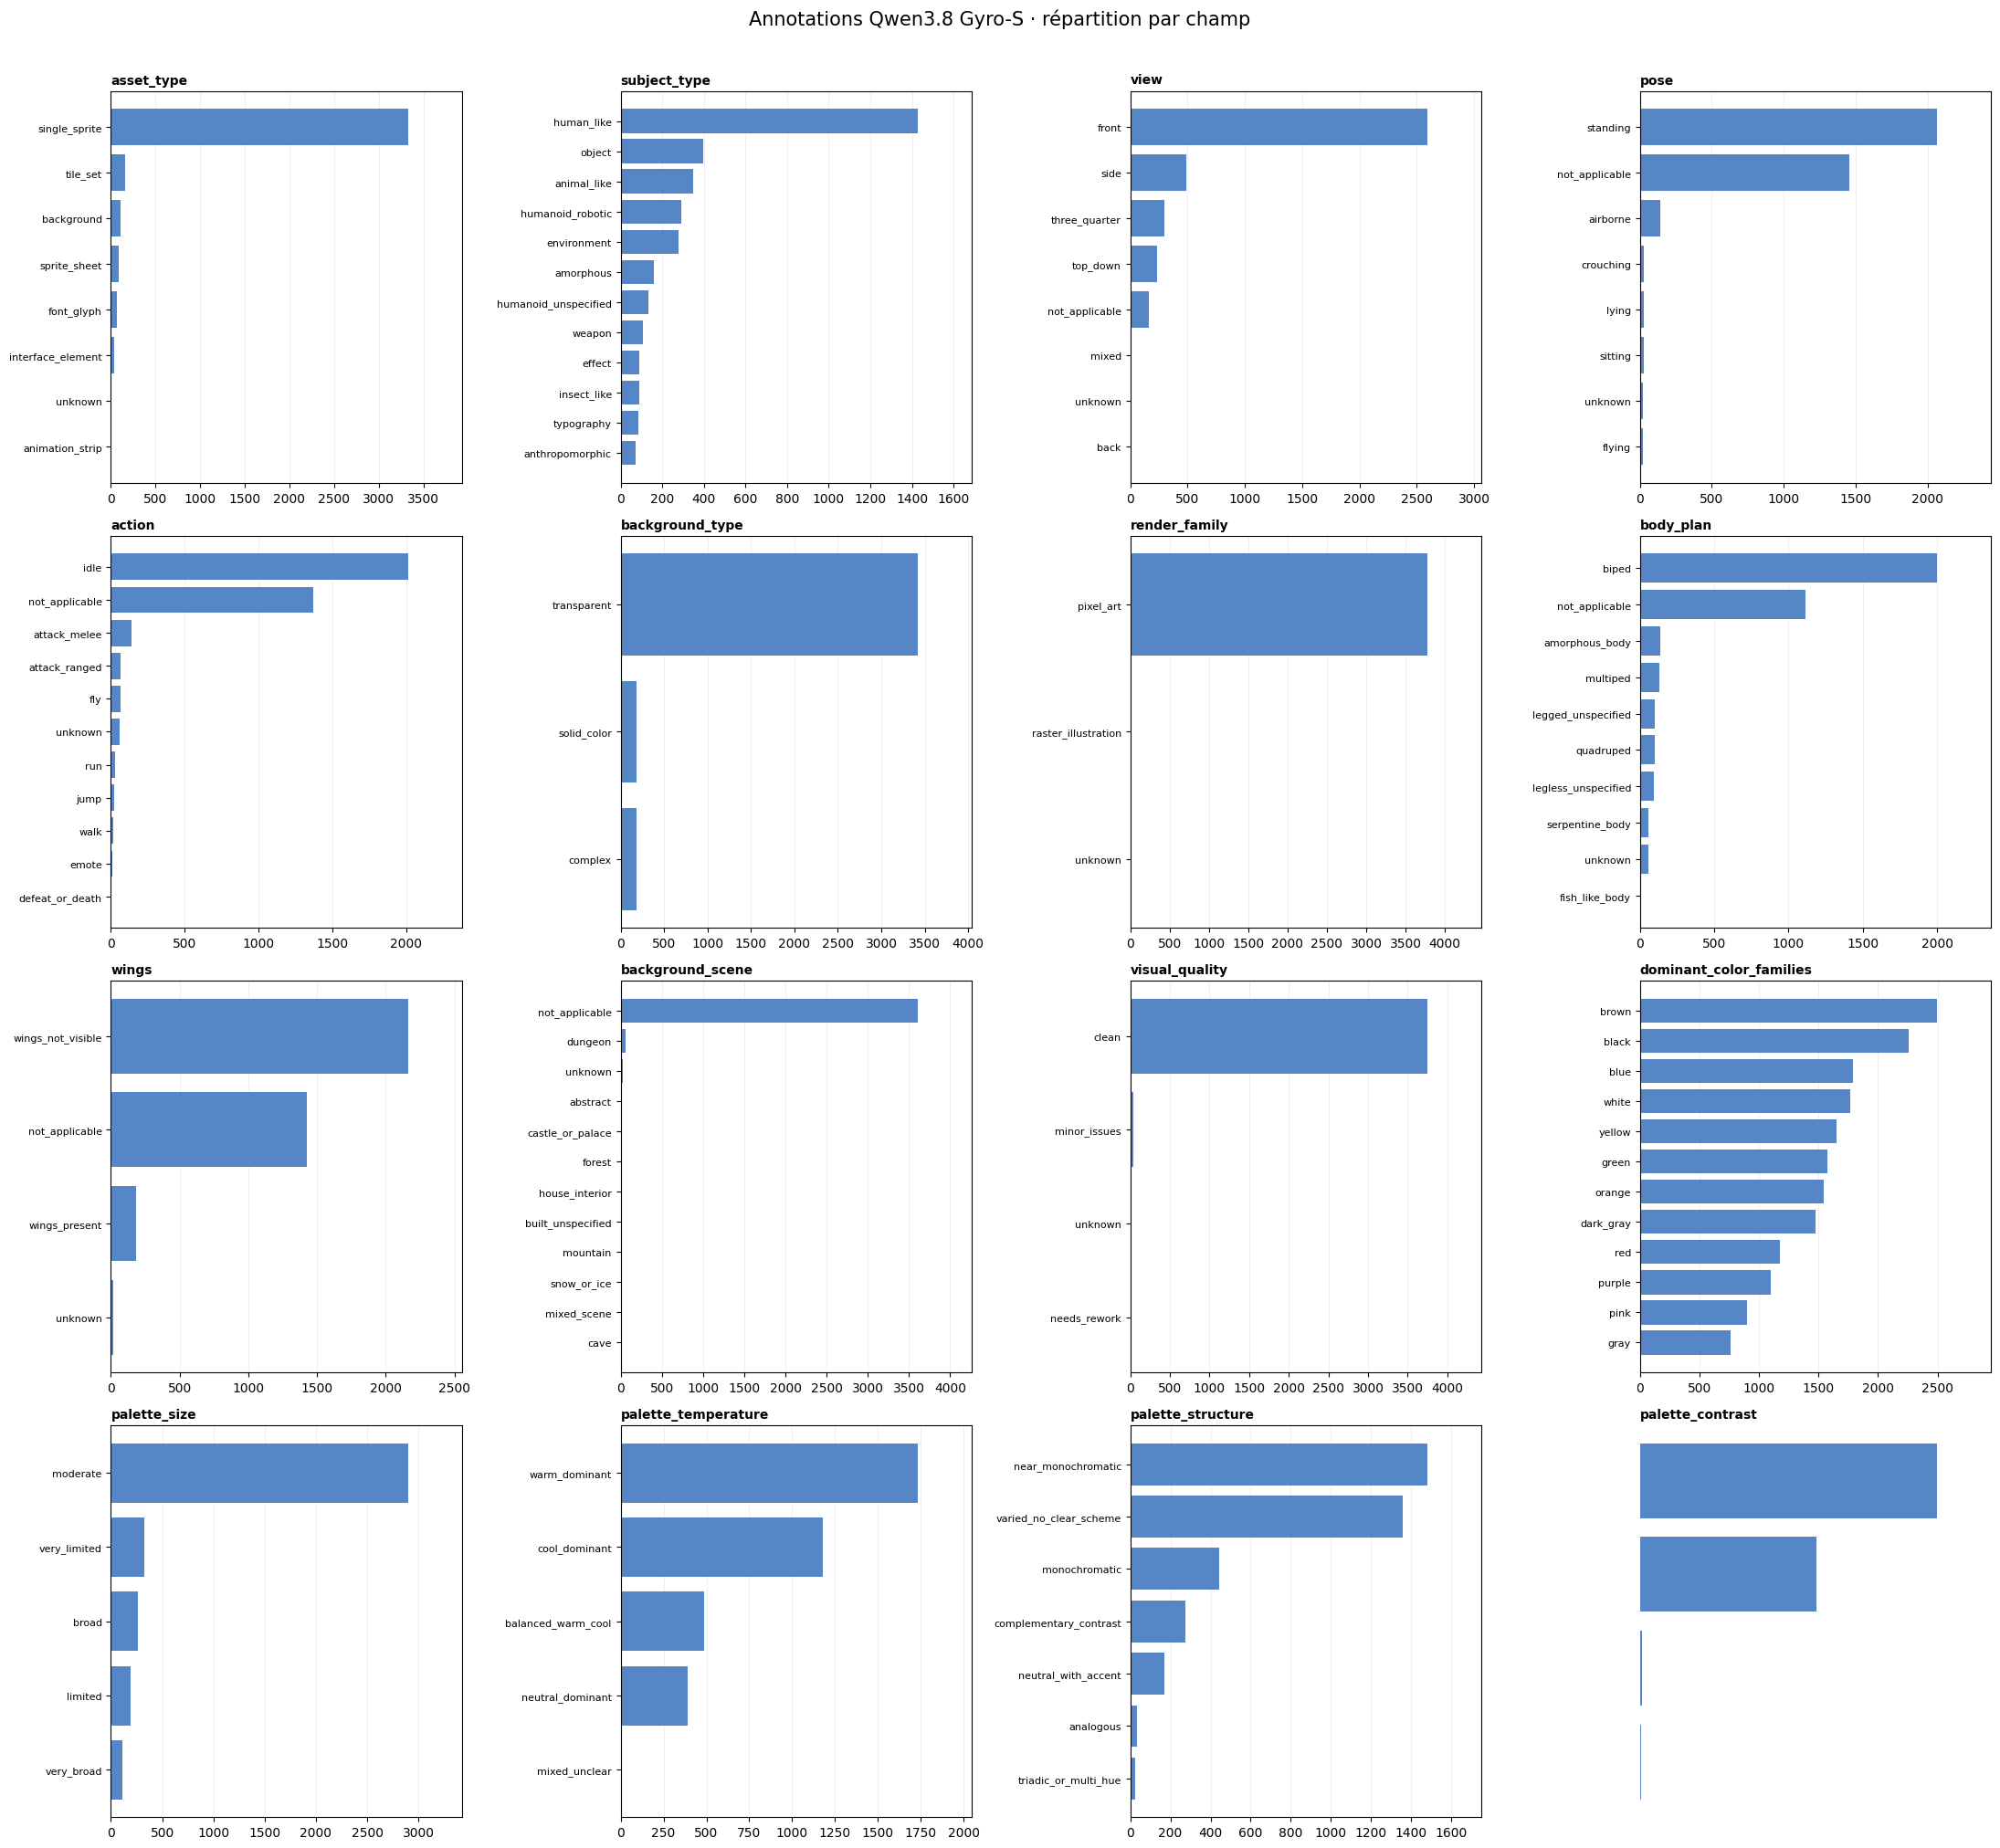

In [3]:
TAXONOMY_FIELDS = [
    'asset_type', 'subject_type', 'view', 'pose', 'action',
    'background_type', 'render_family', 'body_plan', 'wings',
    'background_scene', 'visual_quality', 'dominant_color_families',
    'palette_size', 'palette_temperature', 'palette_structure', 'palette_contrast',
]

def values_for(row, field):
    value = row.get('labels', {}).get(field)
    values = value if isinstance(value, list) else [value]
    return [str(value) if value is not None else '(absent)' for value in values]

fig, axes = plt.subplots(4, 4, figsize=(22, 20))
for ax, field in zip(axes.flat, TAXONOMY_FIELDS):
    counts = Counter()
    for row in qwen_rows:
        counts.update(set(values_for(row, field)))
    top = counts.most_common(12)
    if top:
        names, numbers = zip(*top)
        ax.barh(list(names)[::-1], list(numbers)[::-1], color='#5686c5')
        ax.set_xlim(0, max(numbers) * 1.18)
    ax.set_title(field, loc='left', fontsize=10, fontweight='bold')
    ax.tick_params(axis='y', labelsize=8)
    ax.grid(axis='x', alpha=.2)
    ax.set_axisbelow(True)
axes.flat[-1].axis('off')
fig.suptitle('Annotations Qwen3.8 Gyro-S · répartition par champ', fontsize=15, y=1.01)
fig.tight_layout()
plt.show()


## Qualité, rework et couverture

`visual_quality` décrit l’état visuel estimé par Qwen. `need_rework` est une autre prédiction ; les deux valeurs sont comparées pour repérer les éventuelles incohérences. Les annotations `auto_labeled` restent à vérifier même si elles sont évaluées `clean`.


In [4]:
quality_audit = Counter(
    (row.get('labels', {}).get('visual_quality', '(absent)'), row.get('need_rework', '(absent)'))
    for row in qwen_rows
)
audit_df = pd.DataFrame([
    {'visual_quality': quality, 'need_rework': rework, 'images': count}
    for (quality, rework), count in quality_audit.most_common()
])
display(audit_df)

coverage_rows = []
for field in TAXONOMY_FIELDS:
    missing = sum(not row.get('labels', {}).get(field) for row in qwen_rows)
    unknown = sum('unknown' in values_for(row, field) for row in qwen_rows)
    not_applicable = sum('not_applicable' in values_for(row, field) for row in qwen_rows)
    coverage_rows.append({
        'champ': field,
        'manquant': missing,
        'unknown': unknown,
        'not_applicable': not_applicable,
        'renseigné': len(qwen_rows) - missing,
    })
display(pd.DataFrame(coverage_rows).set_index('champ'))


,visual_quality,need_rework,images
0,clean,False,3753
1,minor_issues,False,35
2,unknown,None,1
3,needs_rework,True,1


,manquant,unknown,not_applicable,renseigné
champ,,,,
asset_type,0,5,0,3790
subject_type,0,7,0,3790
view,0,7,160,3790
pose,0,20,1457,3790
action,0,58,1371,3790
background_type,0,0,0,3790
render_family,0,1,0,3790
body_plan,0,55,1112,3790
wings,0,17,1424,3790


## Analyse des couleurs et palettes

Ces tableaux détaillent les familles de couleurs et les caractéristiques de palette proposées par Qwen3.8. Les familles comptent le nombre d’images contenant chaque couleur. La taille, la température, la structure et le contraste sont des catégories estimées, pas des mesures colorimétriques exactes.


In [5]:
color_counts = Counter()
for row in qwen_rows:
    color_counts.update(set(values_for(row, 'dominant_color_families')))
color_table = pd.DataFrame(color_counts.most_common(), columns=['famille de couleur', 'images'])
display(color_table)

for field in ('palette_size', 'palette_temperature', 'palette_structure', 'palette_contrast'):
    counts = Counter(row.get('labels', {}).get(field, '(absent)') for row in qwen_rows)
    display(pd.DataFrame(counts.most_common(), columns=[field, 'images']))

palette_cross = pd.crosstab(
    [row.get('labels', {}).get('palette_size', '(absent)') for row in qwen_rows],
    [row.get('labels', {}).get('palette_temperature', '(absent)') for row in qwen_rows],
    margins=True,
)
display(palette_cross)


,famille de couleur,images
0,brown,2498
1,black,2260
2,blue,1790
3,white,1766
4,yellow,1650
5,green,1575
6,orange,1541
7,dark_gray,1475
8,red,1174
9,purple,1100


,palette_size,images
0,moderate,2902
1,very_limited,324
2,broad,263
3,limited,188
4,very_broad,113


,palette_temperature,images
0,warm_dominant,1733
1,cool_dominant,1179
2,balanced_warm_cool,487
3,neutral_dominant,390
4,mixed_unclear,1


,palette_structure,images
0,near_monochromatic,1482
1,varied_no_clear_scheme,1359
2,monochromatic,445
3,complementary_contrast,275
4,neutral_with_accent,171
5,analogous,34
6,triadic_or_multi_hue,24


,palette_contrast,images
0,moderate,2362
1,high,1405
2,low,14
3,not_applicable,9


col_0,balanced_warm_cool,cool_dominant,mixed_unclear,neutral_dominant,warm_dominant,All
row_0,,,,,,
broad,38,83,0,91,51,263
limited,10,55,0,54,69,188
moderate,435,962,1,155,1349,2902
very_broad,4,40,0,42,27,113
very_limited,0,39,0,48,237,324
All,487,1179,1,390,1733,3790


## Exemples aléatoires d’annotations

Change `N_EXEMPLES` ou `GRAINE` pour parcourir un autre échantillon. Les images source sont rendues directement dans une grille du notebook, avec leur chemin et leur résolution. Elles sont cherchées dans le cache local puis récupérées depuis le dataset HF privé si nécessaire.


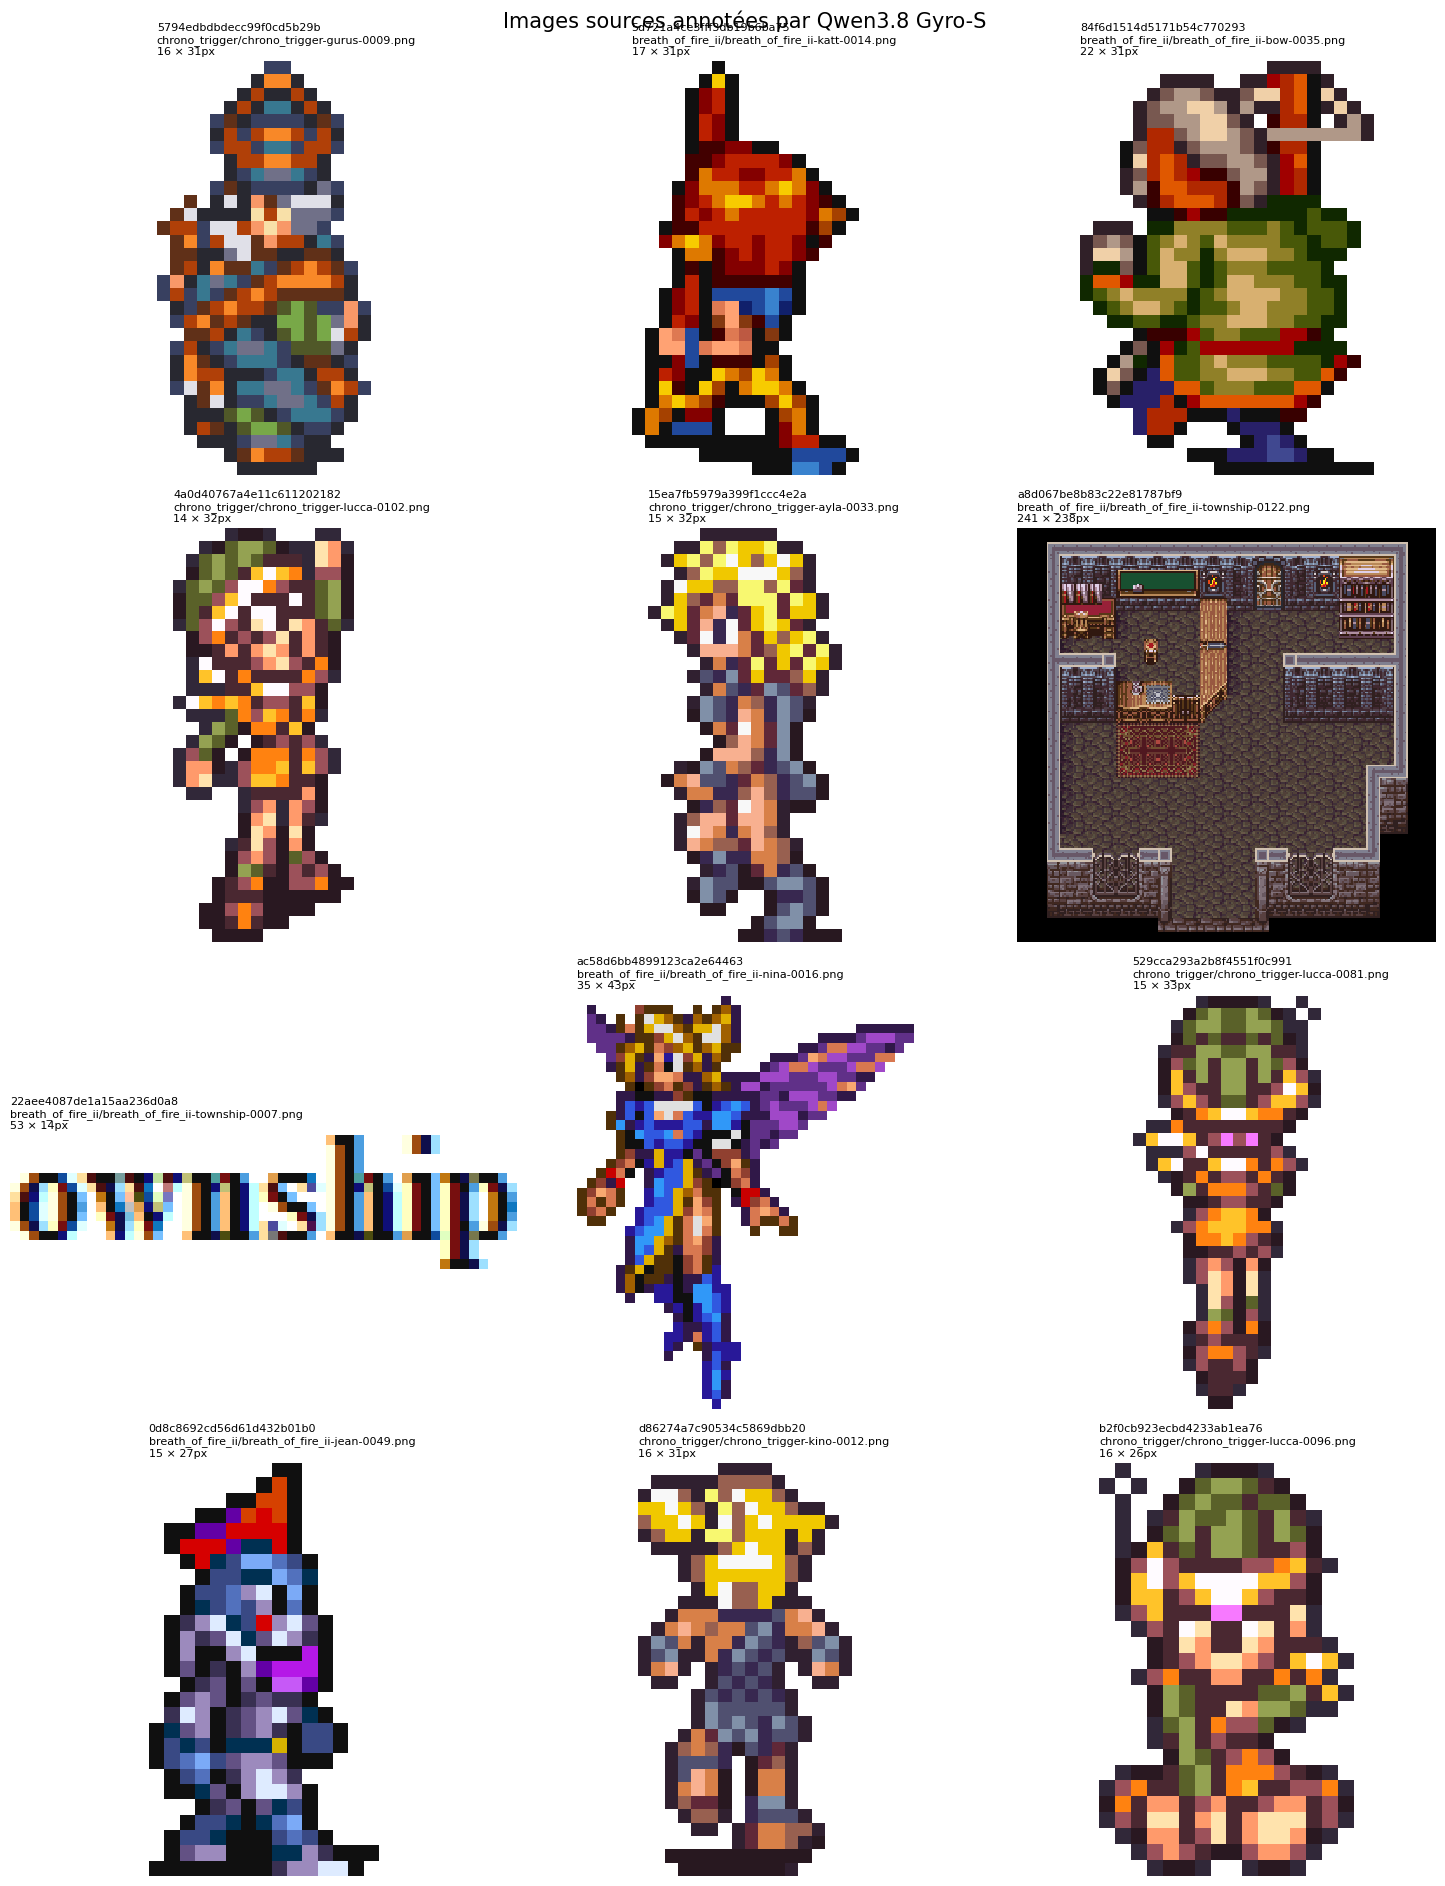


5794edbdbdecc99f0cd5b29b · chrono_trigger/chrono_trigger-gurus-0009.png
Caption Qwen : Pixel art sprite of a humanoid figure with orange armor-like elements, blue-gray body parts, and green accents, standing against a transparent background.
Qualité : clean · need_rework : False


,Taxonomies Qwen3.8
asset_type,single_sprite
subject_type,human_like
view,front
pose,standing
action,idle
background_type,transparent
render_family,pixel_art
body_plan,biped
wings,wings_not_visible
background_scene,not_applicable



5d721a4ce3fff3db19b6ba75 · breath_of_fire_ii/breath_of_fire_ii-katt-0014.png
Caption Qwen : Side-view pixel-art sprite of a humanoid robotic figure with orange and yellow armor and blue accents, standing against a transparent background.
Qualité : clean · need_rework : False


,Taxonomies Qwen3.8
asset_type,single_sprite
subject_type,humanoid_robotic
view,side
pose,standing
action,idle
background_type,transparent
render_family,pixel_art
body_plan,biped
wings,wings_not_visible
background_scene,not_applicable



84f6d1514d5171b54c770293 · breath_of_fire_ii/breath_of_fire_ii-bow-0035.png
Caption Qwen : Pixel-art sprite of a humanoid figure in profile facing left, standing upright. The figure wears a green tunic with orange trim, blue legs, and a gray head with orange accents, on a transparent background.
Qualité : clean · need_rework : False


,Taxonomies Qwen3.8
asset_type,single_sprite
subject_type,human_like
view,side
pose,standing
action,idle
background_type,transparent
background_scene,not_applicable
render_family,pixel_art
body_plan,biped
wings,wings_not_visible


... (14 outputs left out)


d86274a7c90534c5869dbb20 · chrono_trigger/chrono_trigger-kino-0012.png
Caption Qwen : Pixel art sprite of a standing humanoid figure with bright yellow hair, brown skin, and a dark blue-gray outfit, on a transparent background.
Qualité : clean · need_rework : False


,Taxonomies Qwen3.8
asset_type,single_sprite
subject_type,human_like
view,front
pose,standing
action,idle
background_type,transparent
background_scene,not_applicable
render_family,pixel_art
body_plan,biped
wings,wings_not_visible



b2f0cb923ecbd4233ab1ea76 · chrono_trigger/chrono_trigger-lucca-0096.png
Caption Qwen : Pixel art sprite of a humanoid figure with green hair or headwear, orange clothing, and a pink accent, shown against a transparent background.
Qualité : clean · need_rework : False


,Taxonomies Qwen3.8
asset_type,single_sprite
subject_type,human_like
view,front
pose,sitting
action,idle
background_type,transparent
render_family,pixel_art
body_plan,biped
wings,wings_not_visible
background_scene,not_applicable


In [2]:
# Charge le token depuis l’environnement ou les fichiers .env connus, sans jamais l’imprimer.
for env_file in (PROJECT_ROOT / '.env', PROJECT_ROOT / 'training/.env', Path.home() / 'iris-sprite-lora/training/.env'):
    if not env_file.is_file():
        continue
    for line in env_file.read_text(encoding='utf-8').splitlines():
        key, separator, value = line.partition('=')
        if separator and key.strip() in {'HF_TOKEN', 'HUGGINGFACE_HUB_TOKEN'}:
            os.environ.setdefault(key.strip(), value.strip().strip('"').strip("'"))
            break
HF_TOKEN = os.environ.get('HF_TOKEN') or os.environ.get('HUGGINGFACE_HUB_TOKEN') or True

N_EXEMPLES = 12
GRAINE = 42
TELECHARGER_IMAGES_HF = True  # False pour n’afficher que les images déjà en cache.

cache_roots = [PROJECT_ROOT / 'notebook/training/iris_sprite_lora_work/source_images']
image_sample = random.Random(GRAINE).sample(qwen_rows, min(N_EXEMPLES, len(qwen_rows)))
image_records = []
for row in image_sample:
    source = row.get('source', {})
    relative_path = str(source.get('relative_path', '')).replace('\\', '/')
    root_name = str(source.get('root', 'data'))
    image_path = next((root / root_name / relative_path for root in cache_roots if (root / root_name / relative_path).is_file()), None)
    if image_path is None and TELECHARGER_IMAGES_HF and relative_path:
        try:
            image_path = Path(hf_hub_download(
                repo_id=DATASET_REPO, repo_type='dataset',
                filename=f'data/{relative_path}', token=HF_TOKEN,
            ))
        except Exception:
            image_path = None
    image_records.append((row, image_path))

# Matplotlib rend les images comme de vraies sorties image du notebook, avec la source sous chaque vignette.
columns = min(3, len(image_records))
rows_count = (len(image_records) + columns - 1) // columns
fig, axes = plt.subplots(rows_count, columns, figsize=(15, 4.8 * rows_count), squeeze=False)
for ax, (row, image_path) in zip(axes.flat, image_records):
    ax.axis('off')
    if image_path is not None and image_path.is_file():
        try:
            with Image.open(image_path) as image:
                ax.imshow(image.convert('RGBA'), interpolation='nearest')
                dimensions = f'{image.width} × {image.height}px'
        except OSError:
            dimensions = 'image illisible'
            ax.text(.5, .5, dimensions, ha='center', va='center', transform=ax.transAxes)
    else:
        dimensions = 'image indisponible'
        ax.text(.5, .5, dimensions, ha='center', va='center', transform=ax.transAxes)
    asset_id = str(row.get('asset_id', '(id absent)'))
    relative_path = str(row.get('source', {}).get('relative_path', '(source absente)'))
    ax.set_title(f'{asset_id}\n{relative_path}\n{dimensions}', fontsize=8, loc='left', wrap=True)
for ax in axes.flat[len(image_records):]:
    ax.axis('off')
fig.suptitle('Images sources annotées par Qwen3.8 Gyro-S', fontsize=15)
fig.tight_layout()
display(fig)
plt.close(fig)

# Les captions et taxonomies restent lisibles sous la galerie.
for row, image_path in image_records:
    print(f"\n{row.get('asset_id')} · {row.get('source', {}).get('relative_path')}")
    print('Caption Qwen :', row.get('caption_candidate', '(caption absente)'))
    print('Qualité :', row.get('labels', {}).get('visual_quality'), '· need_rework :', row.get('need_rework'))
    display(pd.Series(row.get('labels', {}), name='Taxonomies Qwen3.8').to_frame())
